In [2]:
import glob
import json
import os
import sys
import zipfile
from os import path as osp
from types import SimpleNamespace

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

REPO = r'C:\Users\janak\OneDrive\Documents\GitHub\ronin'
DOWNLOAD = r'C:\Users\janak\Downloads\FRDR_dataset_538_download_216_202610041243'
DATA_DIR = r'C:\Users\janak\data\ronin'
MODELS_DIR = osp.join(DOWNLOAD, 'Pretrained_Models')

sys.path.insert(0, osp.join(REPO, 'source'))                # lets us import the repo's own model / data code
DEVICE = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print('torch', torch.__version__, '| device:', DEVICE)


def find_sequence(name):
    """Return the folder of a sequence, for both the original FRDR layout and the flat layout."""
    hits = glob.glob(osp.join(DATA_DIR, name)) + glob.glob(osp.join(DATA_DIR, '*', name))
    if not hits:
        raise FileNotFoundError(name)
    return hits[0]

torch 2.11.0+cu128 | device: cuda:0


In [8]:
all_seqs = sorted(glob.glob(osp.join(DATA_DIR, '*', 'info.json')))
rows = []
for p in all_seqs:
    seq_dir = osp.dirname(p)
    info = json.load(open(p))
    rows.append({'seq': osp.basename(seq_dir), 'folder': osp.basename(osp.dirname(seq_dir)),
                 'device': info['device'], 'date': info['date'], 'length_min': info['length'] / 60,
                 'grv_ori_error_deg': info['grv_ori_error']})
seqs = pd.DataFrame(rows)
split_of = {}                                               # sequence -> split, from the filtered lists
for list_path in glob.glob(osp.join(DATA_DIR, 'lists', 'list_*.txt')):
    split = osp.basename(list_path)[5:-4]
    split_of.update({s: split for s in open(list_path).read().split()})
seqs['split'] = seqs.seq.map(split_of)
print(len(seqs), 'sequences')
display(seqs.groupby('split' if split_of else 'folder').agg(n=('seq', 'size'), hours=('length_min', lambda x: x.sum() / 60)).round(2))
seqs.head()

152 sequences


,n,hours
split,,
test_seen,32,5.23
test_unseen,32,5.35
train,72,11.88
val,16,2.41


,seq,folder,device,date,length_min,grv_ori_error_deg,split
0,a000_10,ronin,asus4,02/06/19,8.123917,6.669018,train
1,a000_11,ronin,asus6,01/08/19,4.998083,16.363393,test_seen
2,a000_1,ronin,asus5,01/08/19,5.634083,3.519785,train
3,a000_2,ronin,asus5,01/09/19,4.436167,6.296916,train
4,a000_3,ronin,asus7,01/09/19,5.319000,5.766338,train


In [9]:
SEQ = 'a019_3'                                              # from lists/list_test_unseen.txt
seq_dir = find_sequence(SEQ)
info = json.load(open(osp.join(seq_dir, 'info.json')))
print(seq_dir)
for k, v in info.items():
    print(f'{k:24s} {v}')

C:\Users\janak\data\ronin\a019_3
tango_reference_time     17327829647959.0
type                     annotated
imu_init_gyro_bias       [0.03710100000000001, 0.019271999999999994, -0.010769000000000004]
grv_ori_error            1.323341476670806
imu_acce_scale           [1.0048240196375455, 0.9995435563972708, 1.0011390420037194]
date                     01/18/19
start_frame              3628
imu_end_gyro_bias        [0.036952, 0.018833, -0.011029]
align_tango_to_body      [-0.4505762875903388, -0.4836920221512647, -0.5774526616482457, 0.4791361605263014]
imu_reference_time       17328826642203.0
start_calibration        [0.0, 0.99978524, -0.02072376, 0.0]
ekf_ori_error            10.82740087126475
imu_acce_bias            [0.04702927694369276, 0.12323642332428236, -0.05708953639101507]
gyro_integration_error   6.1255774811680626
device                   samsung1
length                   460.67000009385083
imu_time_offset          0.008349265688593732
end_calibration          [0.0, 0.99

Basic Infor

| field | value | meaning |
|---|---|---|
| date | 01/18/19 | recorded on 18 January 2019 |
| device | samsung1 | phone ID, most likely the other phone (the input phone) |
| type | annotated | the same for every recording; you can ignore it |
| length | 460.67 | the whole recording lasted 460 seconds (7.7 minutes) |
| start_frame | 3628 | skip the first 3,628 rows. At 200 rows per second that's the first 18 seconds, which were setup time. What's left is the 7.4 minutes you saw in cell 5. |

Lining up the two phones' clocks

| field | value | meaning |
|---|---|---|
| tango_reference_time | 17327829647959 | a reading of the Tango phone's clock (about 4.8 hours since it was switched on)[cite: 2] |
| imu_reference_time | 17328826642203 | the other phone's clock reading at the same moment, about 1 second ahead of the Tango phone's[cite: 2] |
| imu_time_offset | 0.0083 | a final fine-tuning of 8 milliseconds[cite: 2] |

Correcting the IMU phone's sensors

| field | value | meaning |
|---|---|---|
| imu_init_gyro_bias | [0.037, 0.019, -0.011] | when lying still, the gyroscope should read 0 but reads this much (rad/s) instead. That's about 2°/s on one axis. Left uncorrected, the phone would seem to spin 120° every minute while sitting still.[cite: 3] |
| imu_end_gyro_bias | [0.037, 0.019, -0.011] | the same error measured again at the end. It's almost identical, so the gyro error stayed steady during the recording, which is good.[cite: 3] |
| imu_acce_bias | [0.05, 0.12, -0.06] | the accelerometer's offset error (m/s²), which is subtracted[cite: 3] |
| imu_acce_scale | [1.005, 1.000, 1.001] | the accelerometer reads up to 0.5% too high or low, and this corrects it[cite: 3] |

Rotations between phones (stored as quaternion

| field | meaning |
|---|---|
| align_tango_to_body | how the Tango phone was turned relative to the person's body. It's used by the body-heading model.[cite: 5] |
| start_calibration | the rotation between the two phones, measured when they were lined up at the start. [0, 0.9998, -0.021, 0] is basically a fixed 180° flip between how the two phones define "world" directions, plus a small leftover angle (-0.021).[cite: 5] |
| end_calibration | the same measurement at the end. The small leftover angle changed from -0.021 to -0.004, and that change is the drift.[cite: 5] |

How much the other phone's orientation estimates drifted by the end

| field | value | meaning |
|---|---|---|
| grv_ori_error | 1.3° | Android's game_rv estimate. Very good.[cite: 6] |
| gyro_integration_error | 6.1° | adding up gyro readings yourself. Worse.[cite: 6] |
| ekf_ori_error | 10.8° | the authors' own sensor fusion. Worst here.[cite: 6] |
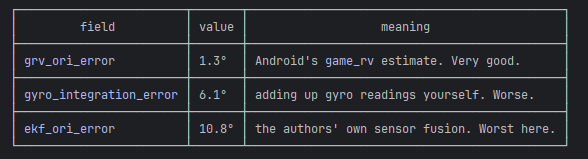

In [10]:
#   raw/imu    - the other phone's sensors, as recorded (uneven rates, first column = timestamp in ns)
#   raw/tango  - the Tango phone's sensors and camera-based pose, as recorded
#   synced     - the other phone's sensors, resampled to 200 Hz on one timeline  -> model inputs
#   pose       - ground truth on the same timeline as synced (tango_* = Tango phone, ekf_ori = other phone)



with h5py.File(osp.join(seq_dir, 'data.hdf5'), 'r') as f:
    f.visititems(lambda name, obj: print(f'{name:28s} {obj.shape} {obj.dtype}')
                 if isinstance(obj, h5py.Dataset) else None)

pose/ekf_ori                 (92135, 4) float64
pose/tango_ori               (92135, 4) float64
pose/tango_pos               (92135, 3) float64
raw/imu/acce                 (201674, 4) float64
raw/imu/game_rv              (100836, 5) float64
raw/imu/gps                  (0,) float64
raw/imu/gravity              (100836, 4) float64
raw/imu/gyro                 (201674, 4) float64
raw/imu/gyro_uncalib         (201674, 4) float64
raw/imu/linacce              (100836, 4) float64
raw/imu/magnet               (48887, 4) float64
raw/imu/magnetic_rv          (0,) float64
raw/imu/pressure             (12222, 2) float64
raw/imu/rv                   (100833, 5) float64
raw/imu/step                 (476, 2) float64
raw/imu/wifi_address         (4212,) object
raw/imu/wifi_values          (4212, 3) int64
raw/tango/acce               (163507, 4) float64
raw/tango/game_rv            (98305, 5) float64
raw/tango/gravity            (98305, 4) float64
raw/tango/gyro               (98305, 4) float64
raw/t

  - Model inputs: synced/ (the other phone, cleaned up and 200 Hz).
  - Correct answers: pose/tango_pos (the Tango phone).
  - Corrections and setup: info.json, which says how to fix the other phone's sensors and where to start.
  - Not needed for training: raw/, which is the original messy recordings from both phones.

In [11]:
with h5py.File(osp.join(seq_dir, 'data.hdf5'), 'r') as f:
    sf = info['start_frame']                                # frames before this are setup / calibration
    t = f['synced/time'][sf:]
    df = pd.DataFrame({'t': t - t[0]})
    for name in ['gyro', 'acce', 'linacce', 'magnet']:      # other phone, 3 axes each
        for i, ax in enumerate('xyz'):
            df[f'{name}_{ax}'] = f[f'synced/{name}'][sf:, i]
    for i, ax in enumerate('xyz'):                          # Tango phone position (ground truth)
        df[f'pos_{ax}'] = f['pose/tango_pos'][sf:, i]
    game_rv = f['synced/game_rv'][sf:]                      # other phone orientation estimate (quaternion)

print(f'{len(df)} frames = {df.t.iloc[-1] / 60:.1f} min at {1 / np.median(np.diff(df.t)):.0f} Hz')
df.describe().T.round(3)

88507 frames = 7.4 min at 200 Hz


,count,mean,std,min,25%,50%,75%,max
t,88507.0,221.265,127.750,0.000,110.633,221.265,331.898,442.530
gyro_x,88507.0,0.005,1.457,-10.907,-0.692,0.004,0.742,12.133
gyro_y,88507.0,0.032,1.345,-17.412,-0.541,0.005,0.604,12.771
gyro_z,88507.0,0.013,1.563,-8.959,-0.789,-0.006,0.935,10.609
acce_x,88507.0,-3.309,7.305,-52.415,-9.224,-3.881,1.133,24.616
acce_y,88507.0,-3.138,5.868,-35.356,-6.618,-3.768,0.049,27.769
acce_z,88507.0,1.108,4.308,-44.969,-0.900,0.721,3.054,40.829
linacce_x,88507.0,-0.404,3.428,-43.743,-1.851,-0.074,1.357,20.988
linacce_y,88507.0,-0.712,3.473,-27.937,-2.500,-0.102,0.972,21.319
linacce_z,88507.0,0.398,2.943,-45.604,-0.648,0.254,1.761,36.402


In [12]:
df

,t,gyro_x,gyro_y,gyro_z,acce_x,acce_y,acce_z,linacce_x,linacce_y,linacce_z,magnet_x,magnet_y,magnet_z,pos_x,pos_y,pos_z
0,0.000,-0.039544,0.094277,0.003511,-1.754307,9.764128,0.406855,0.093370,0.019180,-0.017551,18.039312,-41.180193,-13.266114,0.489610,-0.606296,0.128534
1,0.005,-0.037793,0.092597,0.003290,-1.747985,9.782872,0.407582,0.109556,0.035498,-0.014351,17.869820,-42.378275,-13.934205,0.489452,-0.606263,0.128417
2,0.010,-0.034657,0.090684,0.003472,-1.756642,9.786450,0.417641,0.101567,0.040882,-0.006439,17.700329,-43.576354,-14.602294,0.489301,-0.606227,0.128305
3,0.015,-0.030690,0.091294,0.003291,-1.775212,9.801464,0.414748,0.084436,0.050992,-0.008676,17.411698,-42.834857,-13.999748,0.489151,-0.606184,0.128202
4,0.020,-0.027297,0.090800,0.003818,-1.777331,9.776925,0.423924,0.076306,0.037073,0.001458,17.123068,-42.093361,-13.397202,0.489000,-0.606130,0.128100
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
88502,442.510,-0.334244,-0.068083,0.099953,-8.955809,1.806180,2.582718,0.326093,0.773491,-0.273372,39.446521,-4.792688,7.950237,0.263482,0.052414,-0.038400
88503,442.515,-0.344801,-0.059706,0.072286,-8.926935,1.832299,2.564540,0.351451,0.792283,-0.282541,39.585925,-5.683424,7.726764,0.262831,0.052441,-0.038257
88504,442.520,-0.353734,-0.049685,0.044569,-8.905901,1.839938,2.539847,0.370524,0.800522,-0.307138,39.725326,-6.574130,7.503295,0.262160,0.052463,-0.038115
88505,442.525,-0.364599,-0.040195,0.016346,-8.920255,1.840167,2.502963,0.362024,0.800632,-0.341208,39.655581,-5.981426,7.426352,0.261466,0.052480,-0.037974


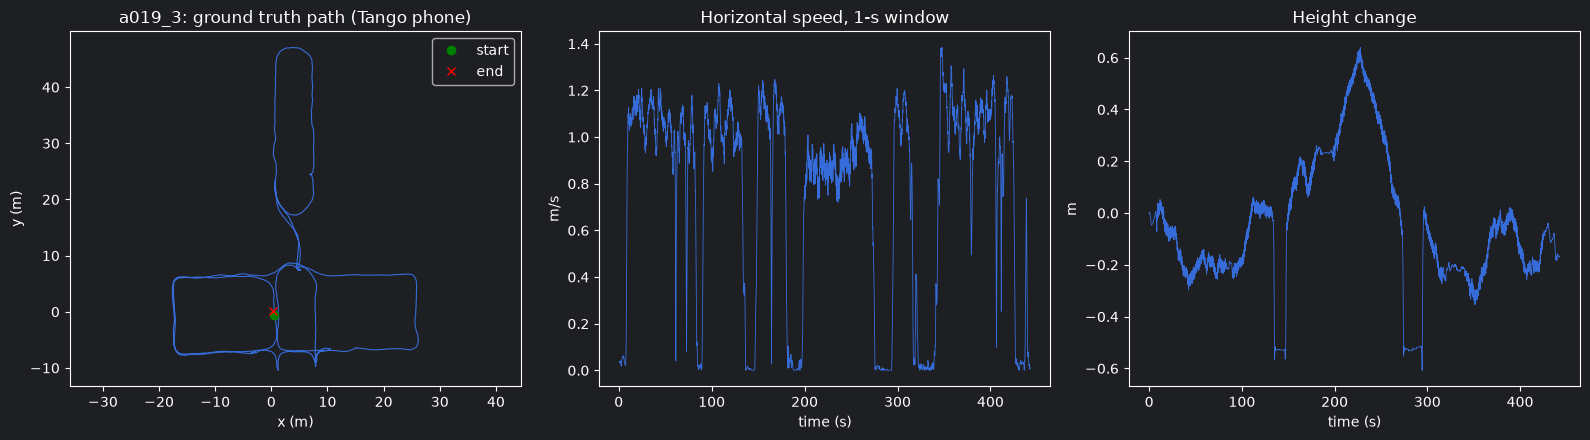

path length 343 m, mean speed 0.77 m/s


In [13]:
w = 200                                                     # 1-second window, same as the RoNIN target
speed = np.linalg.norm(df[['pos_x', 'pos_y']].values[w:] - df[['pos_x', 'pos_y']].values[:-w], axis=1)

fig, axs = plt.subplots(1, 3, figsize=(16, 4.5))
axs[0].plot(df.pos_x, df.pos_y, lw=0.8)
axs[0].plot(df.pos_x.iloc[0], df.pos_y.iloc[0], 'go', label='start')
axs[0].plot(df.pos_x.iloc[-1], df.pos_y.iloc[-1], 'rx', label='end')
axs[0].set(title=f'{SEQ}: ground truth path (Tango phone)', xlabel='x (m)', ylabel='y (m)')
axs[0].axis('equal'); axs[0].legend()
axs[1].plot(df.t[w:], speed, lw=0.6)
axs[1].set(title='Horizontal speed, 1-s window', xlabel='time (s)', ylabel='m/s')
axs[2].plot(df.t, df.pos_z - df.pos_z.iloc[0], lw=0.6)
axs[2].set(title='Height change', xlabel='time (s)', ylabel='m')
plt.tight_layout(); plt.show()
print(f'path length {np.sum(np.linalg.norm(np.diff(df[["pos_x", "pos_y"]].values, axis=0), axis=1)):.0f} m, '
      f'mean speed {speed.mean():.2f} m/s')

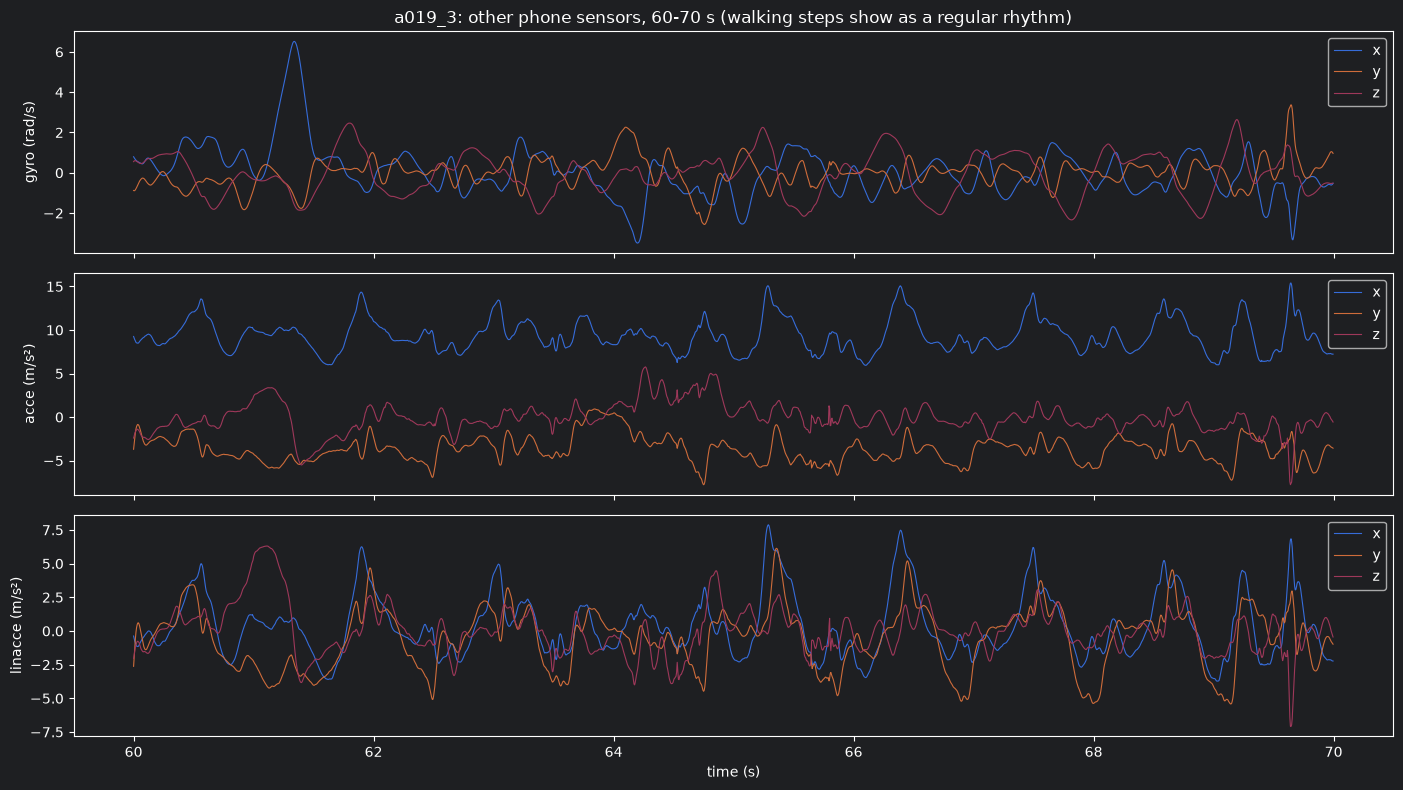

In [14]:
win = (df.t > 60) & (df.t < 70)
fig, axs = plt.subplots(3, 1, figsize=(14, 8), sharex=True)
for ax, (name, unit) in zip(axs, [('gyro', 'rad/s'), ('acce', 'm/s²'), ('linacce', 'm/s²')]):
    for c in 'xyz':
        ax.plot(df.t[win], df[f'{name}_{c}'][win], lw=0.8, label=c)
    ax.set(ylabel=f'{name} ({unit})'); ax.legend(loc='upper right')
axs[0].set_title(f'{SEQ}: other phone sensors, 60-70 s (walking steps show as a regular rhythm)')
axs[-1].set_xlabel('time (s)')
plt.tight_layout(); plt.show()

In [16]:
import ronin_body_heading